# Part 3 — Metrics definition and Analysis
**LOG6307E · Mining Human–AI Collaboration in Software Engineering Repositories**

**RQ2:** **Development Tasks** — What types of tasks are more commonly associated with AI 
teammates? 

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("data/cleaned_pull_requests.csv")

**Metrics included**

- **Task Type rate:** proportion of PRs in each task category.

**1. Task Type rate**

**Task Type rate** measures the percentage of pull requests belonging to a specific task category relative to the total number of pull requests in the analyzed group.

<div align="center">

$$\text{Task type rate} = \frac{\text{PRs in task t}}{\text{Total PRs}} \times 100$$

</div> 

*where $t$ represents a task category.*


In [50]:
def task_type_rate(prs):

    counts = pd.crosstab(
        prs["contribution_type"],
        prs["task_type"]
    )

    counts["Total PRs"] = counts.sum(axis=1)

    percentages = (
        counts.div(counts["Total PRs"], axis=0) * 100
    ).round(2)

    result = pd.concat({
        group: pd.DataFrame(
            [counts.loc[group], percentages.loc[group].map(lambda x: f"{x:.2f}")],
            index=["Count", "Percentage (%)"]
        )
        for group in ["AI", "Human"]
    })

    return result

task_results = task_type_rate(data)
task_results

task_type            build  chore    ci   docs   feat    fix other  perf  \
AI    Count            627    896   411   3886  14434   8098    31   340   
      Percentage (%)  1.87   2.67  1.22  11.58  43.00  24.13  0.09  1.01   
Human Count            614    847   100    519   1935   1765   115    88   
      Percentage (%)  9.31  12.85  1.52   7.87  29.35  26.77  1.74  1.33   

task_type            refactor revert style  test Total PRs  
AI    Count              2286     16   187  2354     33566  
      Percentage (%)     6.81   0.05  0.56  7.01    100.00  
Human Count               367      0    59   183      6592  
      Percentage (%)     5.57   0.00  0.90  2.78    100.00

Text(0, 0.5, 'Percentage of AI-related PRs (%)')

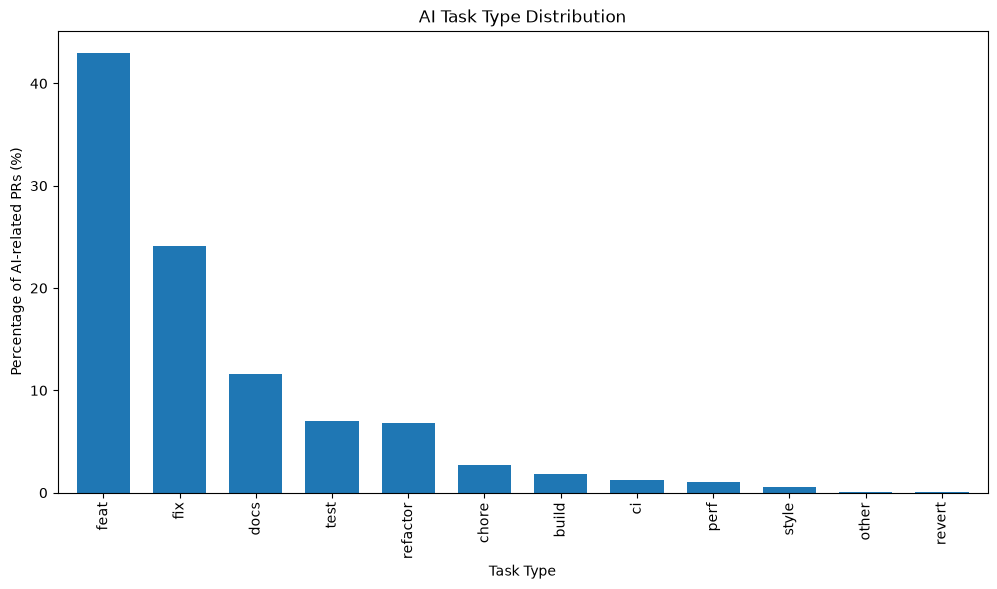

In [ ]:
import matplotlib.pyplot as plt

ai_data = data[data["contribution_type"] == "AI"]

ai_distribution = (
    ai_data["task_type"]
    .value_counts(normalize=True) * 100
)

ax = ai_distribution.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.7
)

plt.title("AI Task Type Distribution")
plt.xlabel("Task Type")
plt.ylabel("Percentage of AI-related PRs (%)")

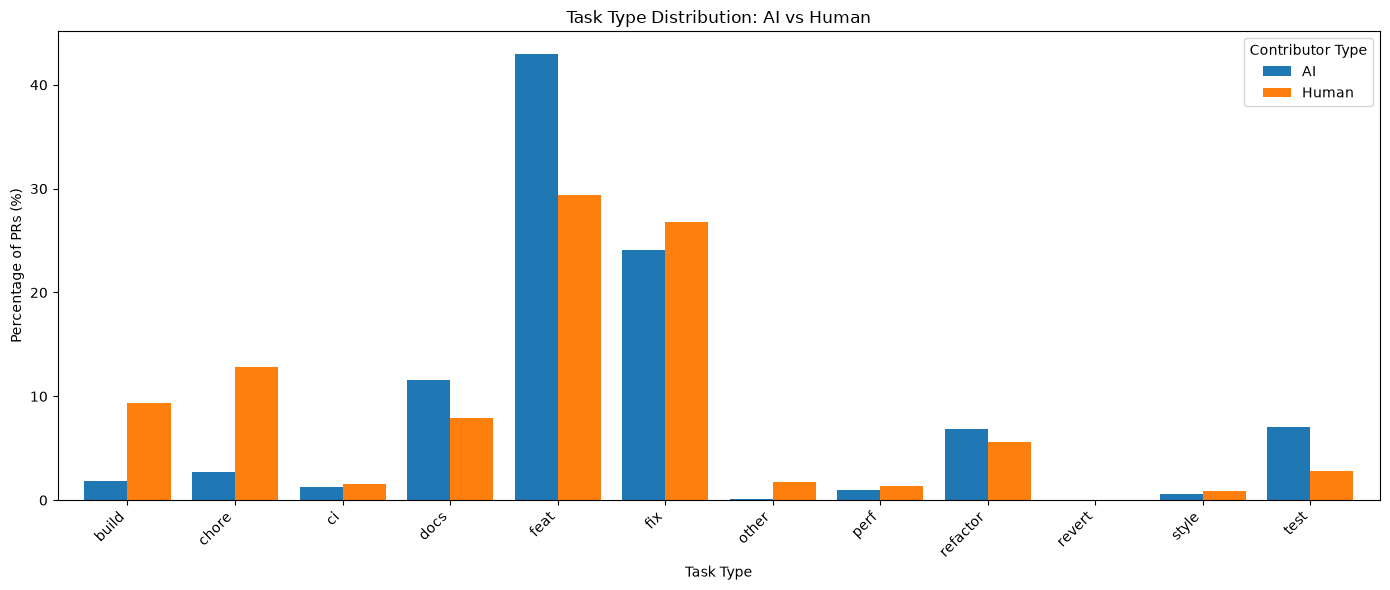

In [ ]:
task_percentages = pd.crosstab(
    data["task_type"],
    data["contribution_type"],
    normalize="columns"
) * 100

ax = task_percentages[["AI", "Human"]].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Task Type Distribution: AI vs Human PRs")
plt.xlabel("Task Type")
plt.ylabel("Percentage of PRs (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Contributor Type")
plt.tight_layout()
plt.show()